# Processing of UAWOS LX80 Radar Altimetry Payload Data
## Authors: Peter Bauer-Gottwein (pbg@ign.ku.dk)

# Preliminaries
This jupyter notebook documents the data processing workflow for the UAWOS LX80 radar altimetry payload. We demonstrate the data processing workflow for one recent example from the Orco River. We only include basic Level-2 and Level-3 processing steps. All necessary Level-1 data, auxiliary data and code files to run this notebook are included in a folder "LX80_processing_example", which is distributed with this notebook and is expected to sit in the directory from which this notebook is run. The LX80_processing_example folder also contains a listing of the UAWOS python environment and a corresponding .yaml file. Please install this environment (e.g. using conda) prior to running the notebook. 

# Level 1 data
A LX80 survey consists of at least one calibration flight and at least one profile flight along the river. The calibration flight provides a site-specific calibration factor for the bin-to-distance conversion of the LX80 radar ranger. 

For each LX80 flight (calibration or profile), 3 output files are generated, which all carry UTC time stamps in the file name:

* A *.position.csv file (e.g. 2025-04-08-12-53-22-position.csv in our example), which contains the drone positioning information from SkyHub
* A *.GEOLUXLX80.csv file (e.g. 2025-04-08-12-53-22-GEOLUXLX80.csv in our example), which contains the drone positioning information along with the LX80 range output
* A *.GEOLUXLX80.sgy file (e.g. 2025-04-08-12-53-22-GEOLUXLX80.sgy in our example), which contains the full-waveform radar ranging output from the LX80

# Auxiliary data
The following auxiliary data files and items are required to process an LX80 dataset:
* A river centerline shapefile (chain_centerline_orco_utm.shp in our case). This shapefile should be in the target projection of the survey (EPSG:32632) in our case. It should be a point shapefile with points every meter along the river centerline. You can produce this file from any river centerline line shapefile, for instance using the QGIS plugin "QChainage".
* Vertical offset between the ppk antenna on the drone and the LX80. This has been measured as 345 mm, but may change whenever a different drone, different mounting etc is used.
* Vertical offset between the rtk antenna on the drone and the LX80. This has been masured as 195 mm, but may change whenever a different drone, different mounting etc is used.
* Vertical offset between the NRA24 radar altimeter (TTF altimeter) and the PPK antenna. This has been measured as 150 mm, but may change whenever a different drone, different mounting etc is used.
* Vertical offset between the NRA24 radar altimeter (TTF altimeter) and the RTK antenna. This has been measured as 0 mm, but may change whenever a different drone, different mounting etc is used.
* A geotiff file giving the elevation of the target geoid above the WGS84 ellipsoid at suitable spatial resolution (e.g. 10m) In our example, we use ITALGEO05 as the geoid and the file is ITALGEO2005_Orco_negative.tif.
* The EPSG code for the target projection (EPSG:32632 in our case)
* The EPSG code for the target geoid (ITALGEO05 in our case)
* The identifier of the chainage field in the attribute table of the centerline shapefile. If you use QChainage, the identifier will be "cngmeters"
* The true WSE of the river (relavite to WGS84) at the place where the calibration flight is conducted. This can be measured with a handheld RTK system (e.g. EMLID Reach). In our case this was 235.86 m.

# Processing Steps

## 1. Calibration Flight
The following cell loads all required packages and modules:

In [3]:
import os
import sys
cwd = os.getcwd()
print(cwd)
my_path = cwd + os.sep + 'LX80_processing_example'
sys.path.insert(0, my_path) # This line adds the "LX80_processing_example" to the python path, so that modules can be found
sys.path.insert(0, cwd) # This line adds the current working directory to the path

from UAWOS_LX80_flight import UAWOS_LX80_flight

H:\UAWOS\uawos_data_processing\new_version


The following cell defines all necessary inputs for the calibration flight:

In [4]:
Orco_general_attributes = dict()

Orco_general_attributes['offset_PPK_LX80'] = (450-105)/1000 #from Sune
Orco_general_attributes['offset_RTK_LX80'] = (300-105)/1000 #from Sune
Orco_general_attributes['offset_PPK_NRA24'] = (450-105-195)/1000 #SPH said NRA is 195 mm from LX80
Orco_general_attributes['offset_RTK_NRA24'] = (300-105-195)/1000 #SPH said NRA is 195 mm from LX80
Orco_general_attributes['geoid_tiff'] = my_path + os.sep + 'ITALGEO2005_Orco_negative.tif'
Orco_general_attributes['xy_EPSG'] = 'EPSG:32632'
Orco_general_attributes['z_EPSG'] = 'ITALGEO05'
Orco_general_attributes['range_cal_fac'] = 0.985
Orco_general_attributes['chainage_file'] = my_path + os.sep + 'chain_centerline_orco_utm.shp'
Orco_general_attributes['chainage_field'] = 'cngmeters'

Orco_cal_attributes = Orco_general_attributes.copy()

Orco_cal_attributes['name_LX80file'] = my_path + os.sep + '2025-04-08-12-35-19-GEOLUXLX80.csv'
Orco_cal_attributes['name_posfile'] = my_path + os.sep + '2025-04-08-12-35-19-position.csv'
Orco_cal_attributes['name_WPfile'] = my_path + os.sep + '2025-04-08-12-35-19-Waypoints.xlsx'
Orco_cal_attributes['name_segyfile'] = my_path + os.sep + '2025-04-08-12-35-19-GEOLUXLX80.sgy'
Orco_cal_attributes['RTK_on'] = True # This flag indicates if RTK was on throughout the flight. 
Orco_cal_attributes['True_WSE_WGS84'] = 235.86

Orco_cal = UAWOS_LX80_flight(Orco_cal_attributes)

UAWOS LX80 flight class constructor


Let us first plot the RTK elevation of the drone during the calibration flight. We see the typical stair pattern:

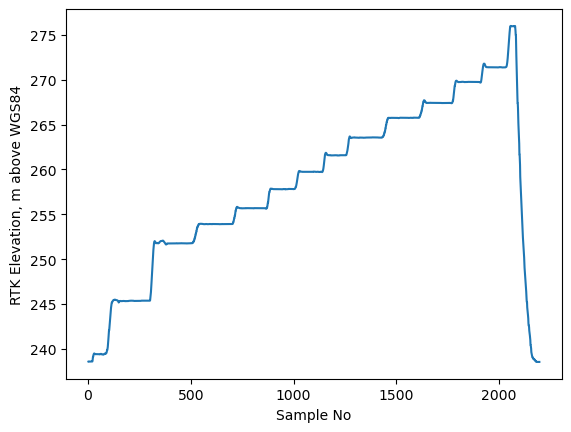

In [6]:
Orco_cal.plot_Alt_RTK_vs_sample_no()

We can also show RTK elevation minus range. We see that the sensor needs calibration.

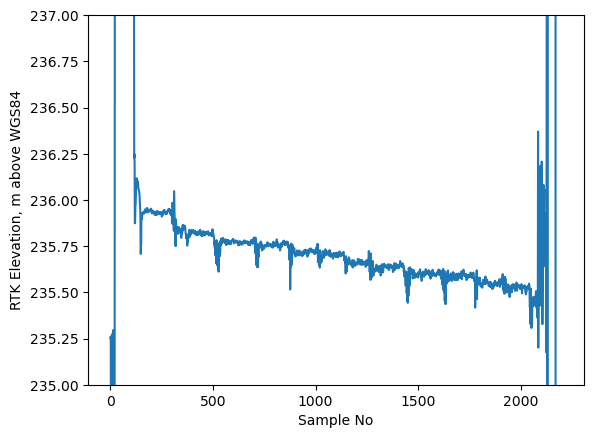

In [7]:
Orco_cal.plot_Alt_RTK_minus_range_vs_sample_no(y_lower=235,y_upper=237)

We can use the "Next WP" column to separate points corresponding to each step in the stair:

In [8]:
Orco_cal.create_WP_file(lt_cutoff=5, ut_cutoff=35)

In [ ]:
Now we inspect how the separation worked:

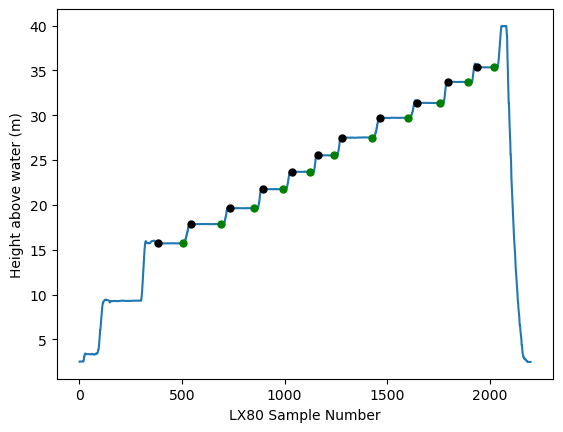

In [10]:
Orco_cal.show_WPfile()

We can see that it worked fine mostly, except for the last step. We can manually adjust the end sample for the last waypoint to 2020 in the Waypoint EXCEL file and do any other manual corrections that may be necessary. . We can now plot the radar and RTK ranges against each other:

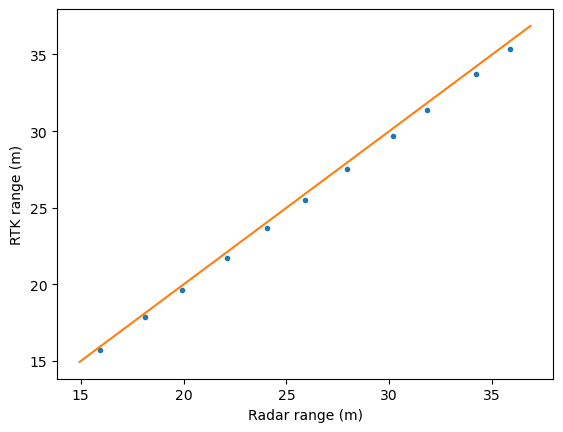

In [11]:
Orco_cal.show_range_corr()

There clearly is a systematic bias. Let's perform a linear regression to obtain the scaling factor:

[[0.98506354]]


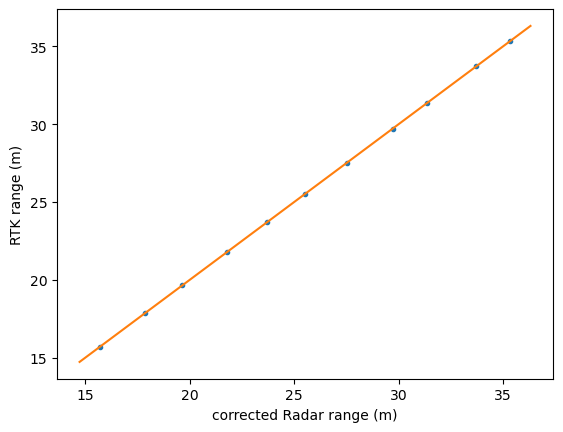

In [12]:
Orco_cal = Orco_cal.calibrate_LX80()

We are now ready to process a profile route.

## 2. Profile flights

We provide inputs for auxiliary data and flight data:

In [18]:
Orco_1_attributes = Orco_general_attributes.copy()
Orco_1_attributes['name_posfile'] = my_path + os.sep + '2025-04-08-12-53-22-position.csv'
Orco_1_attributes['name_ppkfile'] = r'' # if RTK was off during flight, the path to a corresponding ppk file that contains the relevant time stamp range can be provided here
Orco_1_attributes['name_LX80file'] = my_path + os.sep + '2025-04-08-12-53-22-GEOLUXLX80.csv'
Orco_1_attributes['L2_output'] = my_path + os.sep + r'Level_2\2024-07-11-16-57-45.csv'
Orco_1_attributes['L3_output'] = my_path + os.sep + r'Level_3\2024-07-11-16-57-45.csv'
Orco_1_attributes['RTK_on'] = True
Orco_1_attributes['ylim'] = [184,191]
Orco_1_attributes['CL_dist_threshold'] = 100 # this is the threshold used to discard points, i.e. any point further than this from the centerline is discarded.

Orco_1 = UAWOS_LX80_flight(Orco_1_attributes)

UAWOS LX80 flight class constructor


We can now process the flight and save L2 and L3 data:

In [20]:
if not os.path.exists(my_path + os.sep + 'Level_2'):
    os.makedirs(my_path + os.sep + 'Level_2')
if not os.path.exists(my_path + os.sep + 'Level_3'):
    os.makedirs(my_path + os.sep + 'Level_3')
Orco_1 = Orco_1.process_LX80()

Next, we can plot the results, using functions contained in the XS_plotting module.

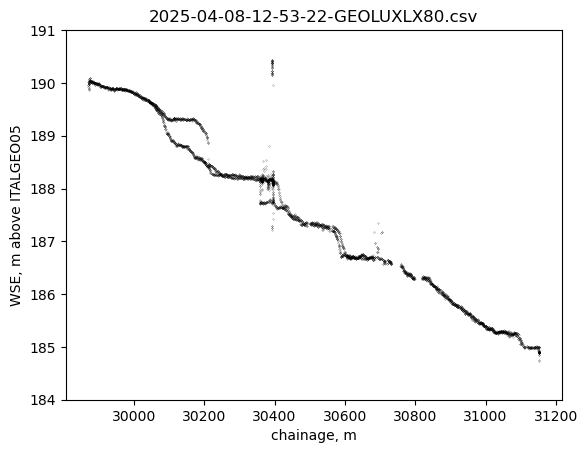

In [21]:
Orco_1.plot_LX80_processed()

## 2. Full waveform data

Sometimes, it can be useful and informative to look at the full waveform (.sgy) output. The following code shows how this can be done.

Number of traces in dataset:  243
Number of samples in each trace:  2048


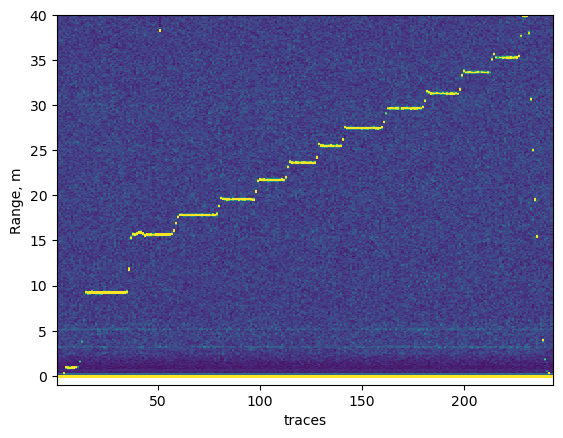

In [13]:
Orco_cal.show_FWF_data()
